# Target Kernel Design for Alignment-Based Multiple Kernel One-Class Classification

This notebook produces the tables and figures of the dissertation.

1. Settings
2. Kernels and alignment weights
3. Target kernels
4. Models
5. Synthetic study
6. Benchmark study
7. Software versions

The full benchmark takes 1–2 hours, so by default the notebook reads the stored results in `results/`. Set `RUN_BENCHMARKS = True` and `RUN_SENSITIVITY = True` to refit everything.

In [1]:
import os
import platform
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import sklearn
import statsmodels
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import nnls
from scipy.stats import friedmanchisquare, rankdata, wilcoxon
from statsmodels.stats.multitest import multipletests

from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import KMeans
from sklearn.manifold import spectral_embedding
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.datasets import load_breast_cancer, load_wine, fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.utils import resample

warnings.filterwarnings("ignore")

## 1. Settings

In [2]:
# Kernel pool: 7 RBF kernels from gamma* x 10^2 down to gamma* x 10^-2 (gamma* = median heuristic)
N_GAMMAS     = 7
GAMMA_SPREAD = 2

# Targets
K_NEIGHBORS = 10      # k_n: kNN-Graph target and spectral affinity graph
K_CLUSTERS  = 3       # k_c: k-Means and Spectral targets

# Synthetic study
NU_SYNTH        = 0.1
N_RUNS_SYNTH    = 20
TEST_SIZE_SYNTH = 0.3     # share of the normal samples held out in each run

# Benchmark study
N_SPLITS = 10
NU_GRID  = (0.01, 0.05, 0.1, 0.2, 0.3)
ALPHA    = 0.05

# Seeds
SEED_SYNTH        = 44    # synthetic run r uses SEED_SYNTH + r
SEED_CV           = 40
SEED_KMEANS       = 42
SEED_SPECTRAL     = 0
SEED_ORACLE_SPLIT = 42
SEED_SHUTTLE      = 4
SEED_MAMMOGRAPHY  = 42

# The method uses "raw" and "qp". Change one of them to reproduce an ablation (Section 6.5).
KERNEL_SCALING = "raw"    # "raw" or "normalized"
SOLVER         = "qp"     # "qp" or "nnls"

# False: read the stored results instead of refitting
RUN_BENCHMARKS  = False
RUN_SENSITIVITY = False

RESULTS_FILES = {("raw", "qp"):        "results/benchmark_results.csv",
                 ("normalized", "qp"): "results/ablation_normalized.csv",
                 ("raw", "nnls"):      "results/ablation_nnls.csv"}
RESULTS_CSV     = RESULTS_FILES[(KERNEL_SCALING, SOLVER)]
SENSITIVITY_CSV = "results/sensitivity_results.csv"
FIG_DIR         = "figures"
os.makedirs(f"{FIG_DIR}/synthetic", exist_ok=True)

METHODS     = ["Oracle-Grid", "Baseline-Median", "MKL-k-Means", "MKL-Spectral", "MKL-kNN"]
MKL_METHODS = ["MKL-kNN", "MKL-Spectral", "MKL-k-Means"]
BASELINES   = ["Oracle-Grid", "Baseline-Median"]

## 2. Kernels and alignment weights

The pool is seven RBF kernels with $\gamma$ log-spaced around the median heuristic $\gamma^*$, from the sharpest ($100\,\gamma^*$) to the broadest ($\gamma^*/100$). The base kernels and the target are centred ($HKH$) and Frobenius-normalised. The weights maximise the centred alignment with the target under $\eta \ge 0$ (Cortes et al.), which is a quadratic program solved as non-negative least squares on the Cholesky factor. The OCSVM is trained on the uncentred combination $\sum_m \eta_m K_m$.

In [3]:
def rbf(A, B=None, gamma=1.0):
    return rbf_kernel(A, B, gamma=gamma)


def median_gamma(X, chunk=256):
    # gamma* = 1 / median of the non-zero pairwise squared distances (computed in blocks of rows)
    X  = np.asarray(X, dtype=np.float64)
    sq = np.empty((len(X), len(X)))
    for start in range(0, len(X), chunk):
        stop = min(start + chunk, len(X))
        sq[start:stop] = np.sum((X[start:stop, None] - X[None, :]) ** 2, axis=-1)
    l = np.median(sq[sq > 0])
    return 1.0 / l if l > 0 else 1.0


def make_base_kernels(X):
    # the kernel pool, ordered from sharpest to broadest
    g_star = median_gamma(X)
    gammas = np.logspace(np.log10(g_star) + GAMMA_SPREAD, np.log10(g_star) - GAMMA_SPREAD, num=N_GAMMAS)
    kernels = [(lambda A, B=None, g=g: rbf(A, B, gamma=g)) for g in gammas]
    return kernels, gammas


def center_kernel(K):
    # H K H, without forming H
    K = K.toarray().astype(np.float64) if sp.issparse(K) else np.array(K, dtype=np.float64, copy=True)
    n    = K.shape[0]
    ones = np.ones(n)
    c, r = K @ ones, K.T @ ones
    K -= np.outer(ones, r) / n
    K -= np.outer(c, ones) / n
    K += c.sum() / n ** 2
    return K


def normalize_kernel(K):
    norm = np.linalg.norm(K, "fro")
    return K if norm == 0 else K / norm


def combined_kernel(A, B, kernels, weights, scales=None):
    # sum_m eta_m K_m(A, B), divided by s_m for the "normalized" ablation
    result = 0
    for m, (f, w) in enumerate(zip(kernels, weights)):
        coef = w if scales is None else w / scales[m]
        result = result + coef * f(A, B)
    return result


def alignment_weights(Kc_all, Kc_target, ridge=1e-8):
    K_flat = np.array([K.ravel() for K in Kc_all])
    G = K_flat @ K_flat.T                      # inner products of the kernels
    M = G + ridge * np.eye(len(Kc_all))
    b = K_flat @ Kc_target.ravel()             # alignment with the target

    if SOLVER == "qp":     # min v'Mv - 2v'b, v >= 0  <=>  NNLS on ||L'v - L^{-1} b||, with M = L L'
        try:
            L = np.linalg.cholesky(M)
        except np.linalg.LinAlgError:          # numerically indefinite: PSD square root instead
            lam, V = np.linalg.eigh(G)
            L = V * np.sqrt(np.clip(lam, 0, None) + ridge)
        w, _ = nnls(L.T, np.linalg.solve(L, b))
    else:                  # ablation: NNLS on M eta = b
        w, _ = nnls(M, b)
    return np.ones_like(w) / len(w) if w.sum() == 0 else w / w.sum()


def fit_kernel(X_train, kernels, target):
    # alignment weights, the training kernel, and the scales for test kernels (None for "raw")
    Kc_all, norms = [], []
    for f in kernels:
        Kc = center_kernel(f(X_train))
        norms.append(np.linalg.norm(Kc, "fro"))
        Kc_all.append(normalize_kernel(Kc))
    weights = alignment_weights(Kc_all, target)
    del Kc_all
    scales = None if KERNEL_SCALING == "raw" else np.array(norms)
    return combined_kernel(X_train, X_train, kernels, weights, scales), weights, scales

## 3. Target kernels

Each target is built from the standardised normal training samples, then centred and normalised.

| Target | Construction |
|---|---|
| Identity | $I$ (synthetic study only) |
| k-Means | $1/\lvert C\rvert$ for two samples in the same k-Means cluster $C$, else 0 |
| kNN-Graph | 1 if one sample is among the $k_n$ nearest neighbours of the other, else 0 |
| Spectral | as k-Means, with the clusters found by spectral clustering on the kNN graph |

In [4]:
def identity_target(X):
    n = len(X)
    T = -np.ones((n, n)) / n
    np.fill_diagonal(T, 1.0 - 1.0 / n)
    return T / np.sqrt(n - 1)          # (I - 11'/n), already centred, with unit norm


def kmeans_target(X, k_clusters=K_CLUSTERS):
    labels = KMeans(n_clusters=k_clusters, random_state=SEED_KMEANS, n_init=10).fit_predict(X)
    rows, cols, vals = [], [], []
    for c in range(k_clusters):
        idx = np.where(labels == c)[0]
        ii, jj = np.meshgrid(idx, idx, indexing="ij")
        rows.append(ii.ravel()); cols.append(jj.ravel())
        vals.append(np.full(len(idx) ** 2, 1.0 / len(idx)))
    T = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(len(X),) * 2)
    return normalize_kernel(center_kernel(T))


def knn_target(X, k_neighbors=K_NEIGHBORS):
    A = kneighbors_graph(X, n_neighbors=k_neighbors, mode="connectivity", include_self=True, n_jobs=-1)
    A = (0.5 * (A + A.T)).tocsr()
    A.data[:] = 1.0
    return normalize_kernel(center_kernel(A))


def spectral_target(X, k_clusters=K_CLUSTERS, k_neighbors=K_NEIGHBORS):
    A = kneighbors_graph(X, n_neighbors=k_neighbors, mode="connectivity", include_self=True)
    embedding = spectral_embedding((0.5 * (A + A.T)).tocsr(), n_components=k_clusters,
                                   eigen_solver="arpack", random_state=SEED_SPECTRAL)
    labels = KMeans(n_clusters=k_clusters, random_state=SEED_KMEANS, n_init=10).fit_predict(embedding)
    A = np.zeros((len(X), k_clusters))
    for c in range(k_clusters):
        if (labels == c).any():
            A[labels == c, c] = 1.0 / np.sqrt((labels == c).sum())
    return normalize_kernel(center_kernel(A @ A.T))


TARGETS = {
    "Identity":            lambda X, k, k_c: identity_target(X),
    "k-Means":             lambda X, k, k_c: kmeans_target(X, k_c),
    "kNN-Graph":           lambda X, k, k_c: knn_target(X, k),
    "Spectral Clustering": lambda X, k, k_c: spectral_target(X, k_c, k),
}

## 4. Models

- **MKL-OCSVM** (MKL-kNN, MKL-Spectral, MKL-k-Means): an OCSVM on the combined kernel, with weights from the alignment with one target.
- **Baseline-Median**: one RBF kernel at the median heuristic $\gamma^*$.
- **Oracle-Grid**: $\gamma$ chosen from the same kind of grid by AUC-ROC on a labelled 20% validation split, so it sees anomalies, which the other methods never do.

In [5]:
def run_mkl(X_train, X_test, kernels, target_name, nu, k=K_NEIGHBORS, k_c=K_CLUSTERS):
    target = TARGETS[target_name](X_train, k, k_c)
    K_train, weights, scales = fit_kernel(X_train, kernels, target)
    clf = OneClassSVM(kernel="precomputed", nu=nu).fit(K_train)
    K_test = combined_kernel(X_train, X_test, kernels, weights, scales).T
    return clf.decision_function(K_test), clf.predict(K_test)


def run_baseline_median(X_train, X_test, nu):
    clf = OneClassSVM(kernel="rbf", gamma=median_gamma(X_train), nu=nu).fit(X_train)
    return clf.decision_function(X_test), clf.predict(X_test)


def run_oracle_grid(X_train_all, y_train_all, X_test, nu):
    X_tr, X_val, y_tr, y_val = train_test_split(X_train_all, y_train_all, test_size=0.2,
                                                stratify=y_train_all, random_state=SEED_ORACLE_SPLIT)
    _, gammas = make_base_kernels(X_tr[y_tr == 1])
    val_auc = [roc_auc_score(y_val, OneClassSVM(kernel="rbf", gamma=g, nu=nu)
                             .fit(X_tr[y_tr == 1]).decision_function(X_val)) for g in gammas]
    best = gammas[int(np.argmax(val_auc))]
    clf = OneClassSVM(kernel="rbf", gamma=best, nu=nu).fit(X_train_all[y_train_all == 1])
    return clf.decision_function(X_test), clf.predict(X_test)

## 5. Synthetic study

Four two-dimensional datasets. Label +1 is normal, −1 is an outlier.

In [6]:
# label convention: z == 0 -> inlier (+1), z == 1 -> outlier (-1)
_to_array = lambda pts: np.array([(x, y, 1 if z == 0 else -1) for (x, y, z) in pts])

DATASET_A = _to_array([(4.85, 6.05, 0), (5.75, 5.6, 0), (4.75, 5.45, 0), (5.0, 4.95, 0), (5.85, 4.9, 0), (6.7, 5.55, 0), (6.1, 6.45, 0), (5.5, 6.55, 0), (4.9, 7.0, 0), (4.0, 6.6, 0), (4.1, 6.2, 0), (3.5, 5.2, 0), (4.45, 4.75, 0), (5.7, 4.5, 0), (6.9, 6.65, 0), (14.15, 7.65, 0), (11.95, 7.95, 0), (10.7, 8.25, 0), (10.7, 12.0, 0), (10.8, 10.55, 0), (12.65, 10.55, 0), (13.0, 12.5, 0), (14.65, 10.3, 0), (15.8, 11.5, 0), (15.95, 9.05, 0), (13.45, 9.15, 0), (14.85, 6.55, 0), (16.25, 7.25, 0), (16.8, 10.2, 0), (14.7, 12.8, 0), (13.9, 11.5, 0), (11.7, 14.05, 0), (11.8, 12.0, 0), (10.55, 13.25, 0), (9.65, 12.0, 0), (9.65, 10.25, 0), (5.5, 7.35, 0), (6.35, 7.1, 0), (13.3, 6.9, 0), (11.25, 9.25, 0), (12.6, 8.7, 0), (16.75, 11.95, 0), (15.55, 13.15, 0), (14.25, 13.6, 0), (12.7, 13.4, 0), (13.25, 14.9, 0), (14.85, 14.7, 0), (17.6, 11.5, 0), (17.1, 13.75, 0), (16.5, 13.3, 0), (15.95, 14.4, 0), (17.5, 13.15, 0), (17.05, 8.4, 0), (15.25, 8.1, 0), (17.5, 9.3, 0), (17.8, 7.65, 0), (18.5, 10.0, 0), (19.55, 12.15, 0), (18.35, 14.25, 0), (18.7, 12.5, 0), (17.15, 15.6, 0), (14.2, 16.35, 0), (10.6, 14.7, 0), (12.2, 16.05, 0), (8.85, 13.55, 0), (5.05, 0.8, 1), (12.55, 2.3, 1), (9.35, 1.8, 1), (3.05, 10.4, 1),(3.95, 11.4, 1),(4.25, 11.9, 1), (3.05, 14.3, 1), (5.25, 16.3, 1), (6.7, 13.05, 1), (9.75, 17.6, 1), (22.0, 15.3, 1), (21.55, 7.65, 1), (17.95, 3.8, 1), (19.8, 3.15, 1), (19.9, 5.3, 1), (20.7, 9.45, 1), (22.2, 11.2, 1), (20.75, 13.35, 1), (20.1, 15.9, 1), (18.45, 17.6, 1), (16.1, 17.0, 1), (9.0, 15.55, 1), (7.1, 15.0, 1), (4.5, 13.5, 1), (1.75, 11.5, 1), (2.1, 12.7, 1), (4.65, 11.3, 1), (6.25, 9.7, 1), (2.9, 8.1, 1), (1.75, 3.25, 1), (1.15, 5.55, 1), (4.2, 2.85, 1), (6.2, 2.6, 1), (9.95, 3.95, 1), (12.6, 4.35, 1), (14.7, 2.75, 1), (17.15, 1.85, 1), (12.75, 17.5, 1), (11.0, 16.95, 1), (15.0, 18.0, 1), (18.55, 16.15, 1), (15.9, 4.8, 1), (14.55, 9.05, 0), (11.7, 6.9, 0), (10.0, 7.7, 0), (9.6, 8.65, 0), (8.6, 10.35, 0), (8.45, 11.7, 0), (15.3, 15.4, 0), (14.1, 15.25, 0), (13.6, 14.1, 0), (12.25, 15.05, 0), (13.25, 15.85, 0), (11.55, 10.5, 0), (13.7, 10.25, 0), (15.05, 11.05, 0),(14.95, 11.9, 0), (18.75, 11.05, 0), (17.95, 5.9, 1), (20.45, 6.7, 1), (7.8, 16.5, 1)])

In [7]:
DATASET_B = _to_array([(23.4,12.7,0),(23.85,12,0),(24.5,12.3,0),(23.95,13.25,0),(25.1,13,0),(25,12.05,0),(23.45,14.15,0),(25.3,13.95,0),(24.55,14.45,0),(24.7,13,0),(24.55,13.8,0),(23.1,13.65,0),(23.1,15.8,0),(24.75,15.3,0),(23.55,15,0),(22.45,14.7,0),(24,15.85,0),(24.1,14.8,0),(25.6,12.65,0),(24,16.95,0),(23,18.2,0),(21.25,19.6,0),(18.7,20.95,0),(12.85,21.55,0),(10,20.6,0),(9.45,17.7,0),(7.55,14.6,0),(10.7,13.7,0),(13.7,16.2,0),(18.15,16.5,0),(21.3,15.35,0),(20.2,16.45,0),(15.7,19.6,0),(12.35,17.5,0),(9.25,15.5,0),(7.8,18.8,0),(19.3,18.15,0),(21.85,17.2,0),(22.1,16.2,0),(23.05,16.7,0),(15.9,17.15,0),(17.6,18.75,0),(16.2,21.45,0),(12.9,19.5,0),(2.95,17.5,1),(4.85,11.55,1),(11.4,11,1),(16.05,12.3,1),(17.45,13.7,1),(18.55,13.6,1),(20,13.35,1),(19.5,12.4,1),(17.8,13.05,1),(18.6,12.45,1),(19.3,11.35,1),(19.1,10.85,1),(17.75,8.8,1),(16.65,8.85,1),(17.75,9.9,1),(18.9,9.9,1),(18.15,10.9,1),(16.05,9.85,1),(18.05,12.05,1),(17.65,12.35,1),(16.9,13,1),(19.2,13,1),(18.8,11.75,1),(17.85,11.45,1),(17.2,11.4,1),(16.95,12.1,1),(18.65,11.4,1),(17,10.6,1),(16.75,7.7,1),(13.1,5.75,1),(8.65,5.45,1),(5.5,5.8,1),(2.65,8.1,1),(0.6,12.1,1),(5.25,15.15,1),(7.75,12.55,1),(8.8,10.05,1),(5.1,7.65,1),(2.2,11.35,1),(8.4,7.7,1),(11.7,8.25,1),(13.5,9.4,1),(15.5,11.2,1),(13.75,11.6,1),(14.2,10.75,1),(14.7,8.3,1),(16,10.8,1),(16.6,11.4,1),(16.95,9.65,1),(14.8,9.55,1),(16.35,9.05,1),(16.05,7.8,1),(14,6.7,1),(15.7,8.9,1),(15.45,10,1),(12.4,7.3,1),(10.6,5.2,1),(12,9.7,1),(10.25,9.3,1),(15.1,10.35,1),(14.9,11.9,1),(18.7,10.9,1),(18.3,10.25,1),(18.4,13.05,1),(10.2,7.2,1),(6.15,9.5,1),(21.55,18.4,0)])

In [8]:
DATASET_C = _to_array([(26.95,11.475,0),(26.6,13.125,0),(26.3,14.225,0),(27.2,12.025,0),(27.5,13.025,0),(27.6,11.225,0),(28.15,11.925,0),(28.15,12.775,0),(28.5,12.225,0),(28.25,13.525,0),(27.6,13.625,0),(26.95,13.725,0),(27.3,14.525,0),(26.8,12.725,0),(27.8,12.125,0),(26.3,14.875,0),(25.5,15.625,0),(23.9,16.825,0),(22.65,17.475,0),(20.8,18.125,0),(23.2,18.825,0),(22.45,18.475,0),(21.15,20.075,0),(25.5,19.625,0),(26.65,17.875,0),(29,14.725,0),(28.25,14.425,0),(27.95,15.875,0),(27.4,15.925,0),(26.85,15.525,0),(25.55,16.875,0),(24.4,17.825,0),(28.3,17.375,0),(23.75,20.375,0),(20.65,22.075,0),(18.7,23.575,0),(16.2,21.025,0),(15,19.675,0),(14.2,17.325,0),(13.1,15.325,0),(8.9,22.375,0),(11.4,19.725,0),(13.1,23.475,0),(11.9,25.925,0),(16.4,23.725,0),(18.45,20.375,0),(16.9,18.425,0),(22.95,22.925,0),(16.3,26.025,0),(20.4,24.925,0),(24.75,22.225,0),(27.75,20.375,0),(27.75,14.975,0),(28.65,13.175,0),(28.85,13.825,0),(5.6,16.825,1),(6.55,16.925,1),(7.75,17.575,1),(7.8,16.775,1),(6.75,15.975,1),(7.45,16.025,1),(8.05,16.175,1),(7,17.775,1),(6.15,16.375,1),(7.25,16.975,1),(8.5,16.675,1),(8.55,16.075,1),(8.75,15.275,1),(9.3,14.525,1),(9.7,13.675,1),(5.9,15.725,1),(12.15,12.725,1),(16.4,13.025,1),(18.5,13.975,1),(21.45,15.475,1),(23.45,13.525,1),(23.95,9.525,1),(23.45,7.275,1),(19.95,6.275,1),(9.7,6.725,1),(6.5,13.025,1),(6.05,14.825,1),(7.2,14.575,1),(7.8,15.325,1),(8.35,14.275,1),(7.5,13.775,1),(6.15,13.875,1),(7.25,12.725,1),(7.45,10.975,1),(8.8,10.275,1),(8.95,11.925,1),(8.6,12.875,1),(8.15,11.675,1),(10.45,11.825,1),(7.6,9.475,1),(8.35,8.075,1),(9.9,8.675,1),(12.15,9.875,1),(14.2,10.675,1),(10.95,12.975,1),(12.8,11.525,1),(11.3,5.975,1),(14.05,5.025,1),(13.8,7.975,1),(17.5,8.025,1),(22.25,12.275,1),(19.15,11.075,1),(17.35,10.775,1),(21.65,8.075,1),(17,5.975,1),(9.1,19.875,0),(10.05,17.525,0),(21.05,9.775,1),(22.15,4.975,1),(18.25,4.375,1),(25.4,8.325,1),(11.3,15.525,0),(9.75,25.125,0),(9.2,15.675,1),(9.75,15.075,1),(10.15,14.225,1),(8.15,17.375,1),(6.25,17.575,1),(7.95,18.475,1),(7.1,18.475,1)])

In [9]:
DATASET_D = _to_array([(20.375,9.1,0),(20.875,9.6,0),(21.275,10.35,0),(21.175,11.55,0),(20.325,12.75,0),(19.025,14,0),(17.375,14,0),(15.675,13.15,0),(14.475,12.4,0),(13.975,11.05,0),(14.075,9.35,0),(14.525,7.45,0),(15.675,6.05,0),(19.375,5.6,0),(22.525,5.5,0),(25.525,5.95,0),(26.875,7,0),(27.825,8.45,0),(28.425,11,0),(28.575,12.95,0),(29.125,14.9,0),(28.525,16.15,0),(27.375,16.9,0),(25.975,17.8,0),(25.025,18.45,0),(21.025,9.15,0),(22.025,10.95,0),(21.675,9.7,0),(22.725,10.3,0),(22.675,11.6,0),(21.925,12.4,0),(21.325,13.25,0),(21.025,14.6,0),(19.025,15.3,0),(16.575,15.35,0),(14.425,14.85,0),(11.625,12.5,0),(11.075,8.6,0),(13.275,4,0),(22.625,1.65,0),(32.075,5.65,0),(35.225,9.6,0),(33.825,15.05,0),(32.775,17.95,0),(32.775,8.55,0),(31.025,11.65,0),(30.425,8.65,0),(26.375,2.95,0),(29.675,5.95,0),(24.275,3.3,0),(17.675,1.4,0),(16.675,3,0),(20.175,3.15,0),(18.475,3.9,0),(15.225,4.55,0),(13.725,5.9,0),(12.525,8.95,0),(11.675,9.9,0),(12.925,11.1,0),(13.275,13.15,0),(14.825,13.85,0),(11.875,6.75,0),(19.875,2.1,0),(22.075,3.85,0),(33.425,12.75,0),(30.475,17.05,0),(31.525,14.55,0),(20.275,14.05,0),(22.325,13.25,0),(17.975,14.95,0),(16.325,14.8,0),(20.175,15.25,0),(21.725,14.45,0),(22.975,12.55,0),(17.975,11.55,1),(18.425,9.85,1),(18.175,7.85,1),(8.025,3.2,1),(11.525,1.95,1),(8.925,10.05,1),(8.325,14.95,1),(13.625,16.85,1),(25.425,15,1),(24.625,8.9,1),(21.775,16.45,1),(16.025,9.75,1),(19.775,10.65,1),(21.575,7.2,1),(31.025,2.3,1),(36.475,3.6,1),(36.525,11.55,1),(36.225,17.75,1),(15.6,19.4,1),(26.4,20.8,1),(35.35,20.7,1),(29.35,18.45,0),(34.25,10.85,0),(28.8,4,0),(31.55,19.95,1),(20.35,19.4,1),(19.4,12.3,1)])

SYNTHETIC = {"Dataset A": DATASET_A, "Dataset B": DATASET_B,
             "Dataset C": DATASET_C, "Dataset D": DATASET_D}

for name, data in SYNTHETIC.items():
    print(f"{name}: {(data[:, 2] == 1).sum():3d} inliers, {(data[:, 2] == -1).sum():3d} outliers")

Dataset A:  81 inliers,  45 outliers
Dataset B:  45 inliers,  66 outliers
Dataset C:  59 inliers,  66 outliers
Dataset D:  77 inliers,  24 outliers


### 5.1 Target matrices (Dataset D)

Each panel is a target matrix on Dataset D's standardised normal samples, after centring and normalisation. Rows are ordered by polar angle around the centroid.

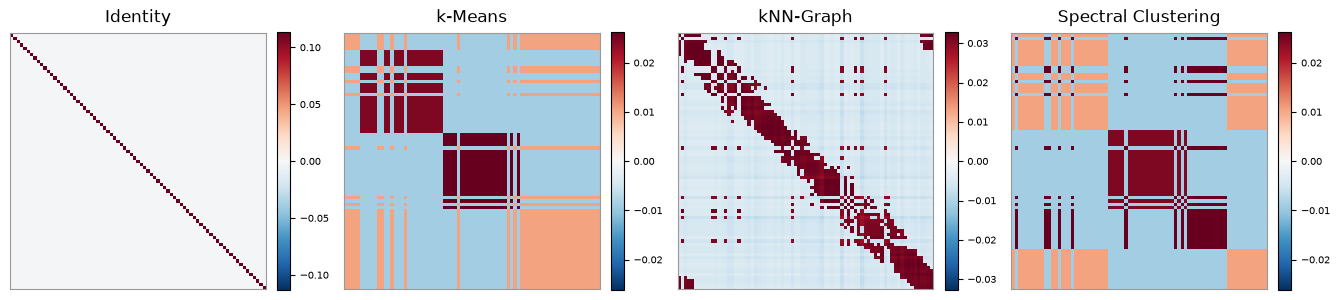

In [10]:
def plot_target_matrices(data, savepath=None):
    X = StandardScaler().fit_transform(data[data[:, 2] == 1, :2])
    c = X.mean(axis=0)
    order = np.argsort(np.arctan2(X[:, 1] - c[1], X[:, 0] - c[0]))

    fig, axes = plt.subplots(1, len(TARGETS), figsize=(13.5, 3.4))
    for ax, (name, build) in zip(axes, TARGETS.items()):
        T = build(X, K_NEIGHBORS, K_CLUSTERS)
        T = np.asarray(T.todense()) if sp.issparse(T) else np.asarray(T)
        M = T[np.ix_(order, order)]
        v = np.percentile(np.abs(M), 99.5) or np.abs(M).max()
        im = ax.imshow(M, cmap="RdBu_r", vmin=-v, vmax=v, interpolation="nearest")
        ax.set_title(name, fontsize=12, pad=8)
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_linewidth(0.8); spine.set_color("#999999")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).ax.tick_params(labelsize=7)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, bbox_inches="tight", dpi=200)
    plt.show()


plot_target_matrices(DATASET_D, savepath=f"{FIG_DIR}/target_matrices.pdf")

### 5.2 Decision boundaries

The OCSVM is fitted on all standardised normal samples ($\nu = 0.1$). Each panel is also saved as a PNG in `figures/synthetic/`.

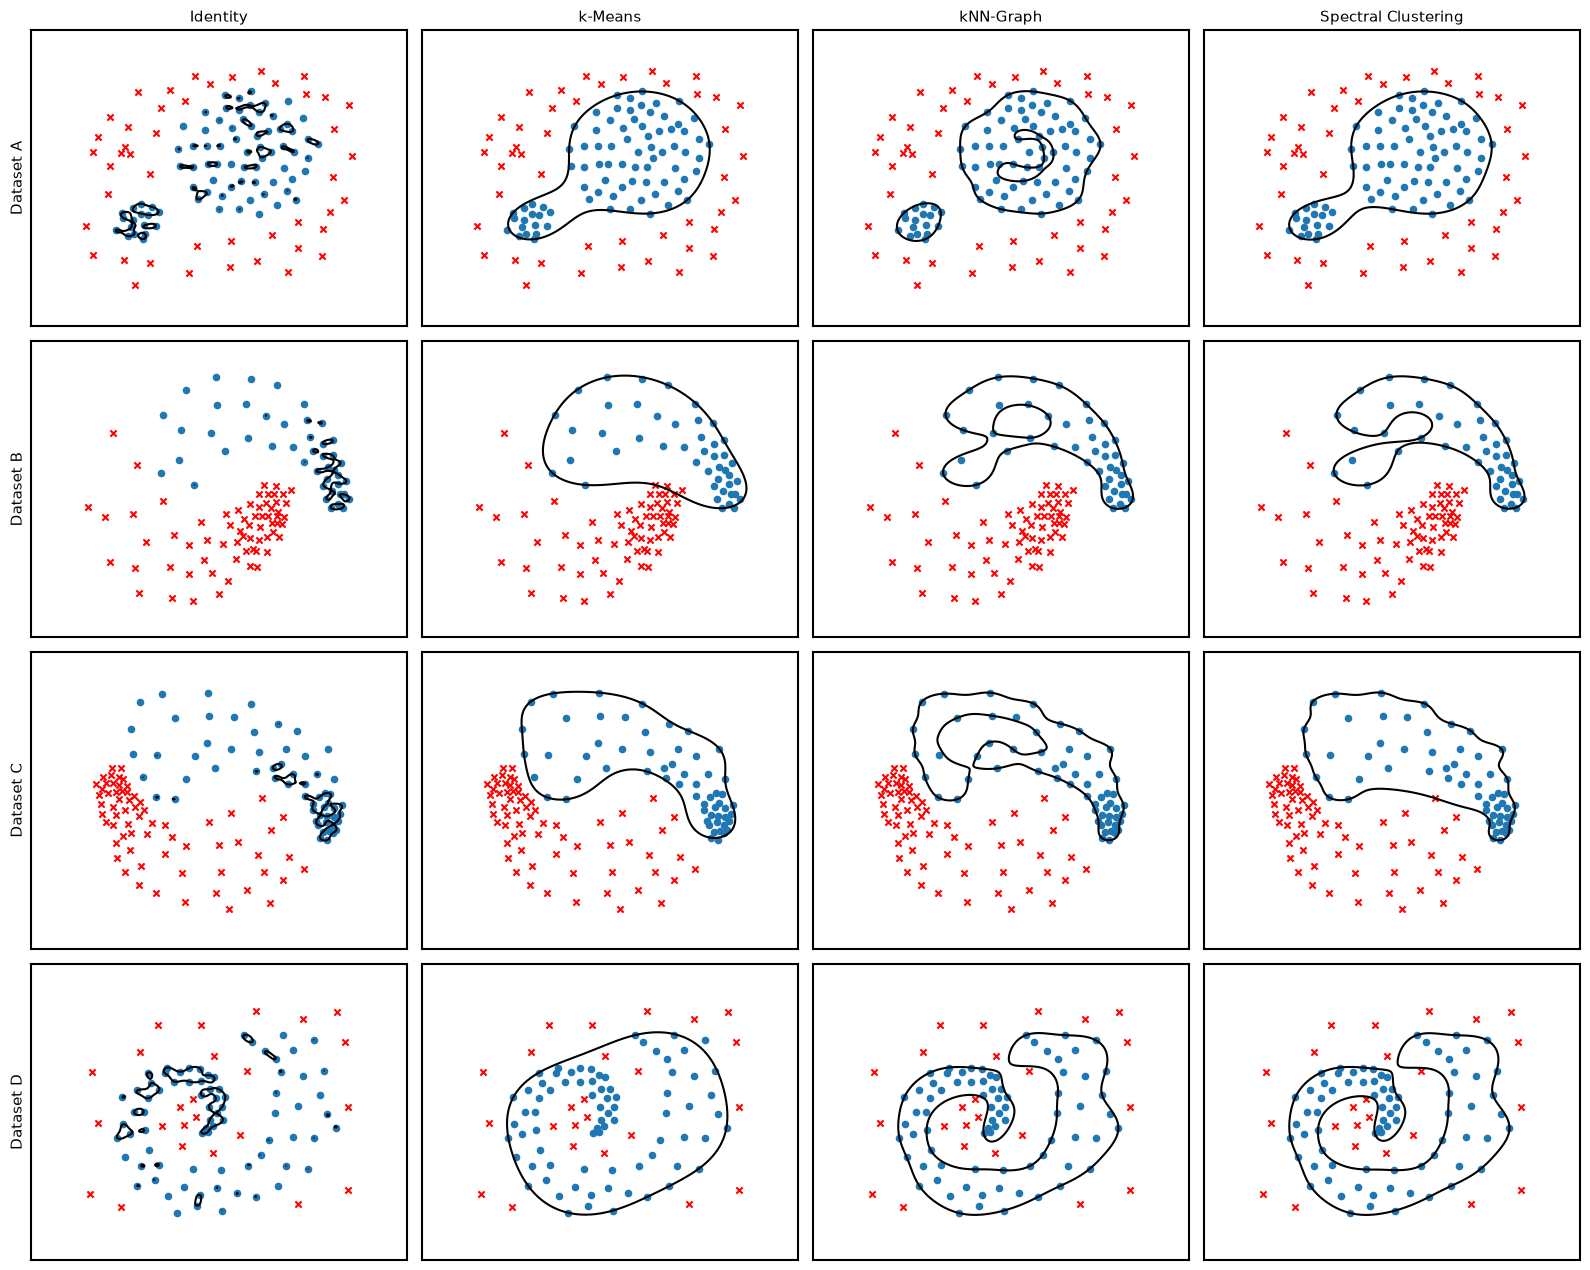

In [11]:
def standardize(data):
    X, y = data[:, :2], data[:, 2]
    scaler = StandardScaler().fit(X[y == 1])
    return scaler.transform(X[y == 1]), scaler.transform(X), y


def fit_synthetic(X_train, kernels, target_name):
    target = TARGETS[target_name](X_train, K_NEIGHBORS, K_CLUSTERS)
    K_train, weights, scales = fit_kernel(X_train, kernels, target)
    return OneClassSVM(kernel="precomputed", nu=NU_SYNTH).fit(K_train), weights, scales


def plot_boundary(ax, X_all, y, X_train, clf, kernels, weights, scales, n=300):
    xx, yy = np.meshgrid(np.linspace(X_all[:, 0].min() - 1, X_all[:, 0].max() + 1, n),
                         np.linspace(X_all[:, 1].min() - 1, X_all[:, 1].max() + 1, n))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = clf.decision_function(combined_kernel(grid, X_train, kernels, weights, scales)).reshape(xx.shape)
    ax.contour(xx, yy, Z, colors="k", levels=[0])
    ax.scatter(X_all[y == 1, 0], X_all[y == 1, 1], s=20, label="Known Class")
    ax.scatter(X_all[y == -1, 0], X_all[y == -1, 1], s=20, marker="x", c="red", label="Outliers")
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_linewidth(1.5); spine.set_color("black")


fig, axes = plt.subplots(4, 4, figsize=(16, 12.8))
for r, (name, data) in enumerate(SYNTHETIC.items()):
    X_train, X_all, y = standardize(data)
    kernels, _ = make_base_kernels(X_train)
    for c, target_name in enumerate(TARGETS):
        clf, weights, scales = fit_synthetic(X_train, kernels, target_name)
        plot_boundary(axes[r, c], X_all, y, X_train, clf, kernels, weights, scales)
        axes[0, c].set_title(target_name, fontsize=11)
        axes[r, 0].set_ylabel(name, fontsize=11)

        single, ax = plt.subplots(figsize=(4, 3.2))
        plot_boundary(ax, X_all, y, X_train, clf, kernels, weights, scales)
        slug = name.lower().replace(" ", "") + "_" + target_name.lower().split()[0].replace("-", "")
        single.savefig(f"{FIG_DIR}/synthetic/{slug}.png", bbox_inches="tight", pad_inches=0.02, dpi=150)
        plt.close(single)
fig.tight_layout()
plt.show()

### 5.3 Kernel shares

Share of each base kernel in the combined kernel of the panels above: $\eta_m \lVert K_m - \bar K_m \rVert_F$, normalised to sum to 1. The kernel's mean entry $\bar K_m$ is removed because a constant added to the kernel does not change the OCSVM. Shares below 0.005 are shown as `--`.

In [12]:
rows = {}
for name, data in SYNTHETIC.items():
    X_train, _, _ = standardize(data)
    kernels, gammas = make_base_kernels(X_train)
    for target_name in TARGETS:
        _, weights, scales = fit_synthetic(X_train, kernels, target_name)
        s = np.ones(N_GAMMAS) if scales is None else scales
        size = np.array([np.linalg.norm(K - K.mean(), "fro") for K in (f(X_train) for f in kernels)])
        share = weights * size / s
        rows[(target_name, name[-1])] = share / share.sum()

shares = pd.DataFrame(rows, index=[f"{g:.3g}" for g in gammas / gammas[N_GAMMAS // 2]]).T
shares.columns.name = "gamma / gamma*"
shares.map(lambda v: f"{v:.2f}" if v >= 0.005 else "--")

,gamma / gamma*,100,21.5,4.64,1,0.215,0.0464,0.01
Identity,A,1.00,--,--,--,--,--,--
k-Means,A,--,--,0.05,0.95,--,--,--
kNN-Graph,A,--,0.02,0.98,--,--,--,--
Spectral Clustering,A,--,--,0.10,0.89,--,--,--
Identity,B,1.00,--,--,--,--,--,--
k-Means,B,--,--,--,1.00,--,--,--
kNN-Graph,B,--,--,0.66,0.34,--,--,--
Spectral Clustering,B,--,--,0.64,0.11,0.25,--,--
Identity,C,1.00,--,--,--,--,--,--
k-Means,C,--,--,0.20,0.80,--,--,--


### 5.4 Synthetic results (Table 2)

Twenty random 70/30 splits of the normal samples. The test set is the held-out normal samples plus all outliers. Values are mean (std) over the runs; F1 is for the outlier class.

In [13]:
def synthetic_scores(data):
    X, y = data[:, :2], data[:, 2]
    X_in, X_out = X[y == 1], X[y == -1]
    scores = {t: {"F1 (anomaly)": [], "AUC-ROC": []} for t in TARGETS}

    for run in range(N_RUNS_SYNTH):
        X_train, X_in_test = train_test_split(X_in, test_size=TEST_SIZE_SYNTH, random_state=SEED_SYNTH + run)
        X_test = np.vstack([X_in_test, X_out])
        y_test = np.hstack([np.ones(len(X_in_test)), -np.ones(len(X_out))])
        scaler = StandardScaler().fit(X_train)
        X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

        kernels, _ = make_base_kernels(X_train)
        for t in TARGETS:
            clf, weights, scales = fit_synthetic(X_train, kernels, t)
            K_test = combined_kernel(X_test, X_train, kernels, weights, scales)
            scores[t]["F1 (anomaly)"].append(f1_score(y_test, clf.predict(K_test), pos_label=-1))
            scores[t]["AUC-ROC"].append(roc_auc_score(y_test == -1, -clf.decision_function(K_test)))

    return pd.DataFrame({t: {m: f"{np.mean(v):.3f} ({np.std(v):.3f})" for m, v in s.items()}
                         for t, s in scores.items()})


pd.concat({name: synthetic_scores(data) for name, data in SYNTHETIC.items()})

Identity        k-Means      kNN-Graph  \
Dataset A F1 (anomaly)  0.783 (0.000)  0.961 (0.021)  0.916 (0.027)   
          AUC-ROC       0.997 (0.003)  0.999 (0.001)  1.000 (0.001)   
Dataset B F1 (anomaly)  0.905 (0.002)  0.935 (0.025)  0.955 (0.020)   
          AUC-ROC       0.990 (0.017)  0.954 (0.038)  0.984 (0.023)   
Dataset C F1 (anomaly)  0.884 (0.004)  0.962 (0.011)  0.944 (0.018)   
          AUC-ROC       0.945 (0.030)  0.982 (0.020)  0.988 (0.016)   
Dataset D F1 (anomaly)  0.670 (0.005)  0.673 (0.034)  0.712 (0.043)   
          AUC-ROC       0.898 (0.041)  0.663 (0.017)  0.812 (0.039)   

                       Spectral Clustering  
Dataset A F1 (anomaly)       0.950 (0.026)  
          AUC-ROC            1.000 (0.001)  
Dataset B F1 (anomaly)       0.952 (0.019)  
          AUC-ROC            0.983 (0.029)  
Dataset C F1 (anomaly)       0.950 (0.020)  
          AUC-ROC            0.982 (0.019)  
Dataset D F1 (anomaly)       0.711 (0.054)  
          AUC-ROC            0.773 (0.072)

## 6. Benchmark study

### 6.1 Datasets (Table 3)

Nine datasets cast as one-class problems (normal = +1, anomaly = −1). Breast Cancer and Wine come with scikit-learn; the others are downloaded from OpenML on first use. ν is the value in `NU_GRID` closest to the dataset's anomaly rate. The Fisher score is the squared Mahalanobis distance between the class means.

In [14]:
def openml(data_id, **kw):
    return fetch_openml(data_id=data_id, **kw)


def load_ionosphere():
    ds = openml(59, as_frame=True)
    return ds.data.values.astype(float), np.where(ds.target.values.ravel() == "g", 1, -1)


def load_breast_cancer_occ():
    d = load_breast_cancer()
    return d.data, np.where(d.target == 1, 1, -1)


def load_wine_occ():
    d = load_wine()
    return d.data, np.where(d.target == 2, -1, 1)


def load_glass():
    ds = openml(41, as_frame=True)
    normal = ["build wind float", "build wind non-float", "vehic wind float"]
    return ds.data.values.astype(float), np.where(np.isin(ds.target.values.ravel(), normal), 1, -1)


def load_shuttle():
    ds = openml(40685, as_frame=True)
    X, y = ds.data.values.astype(float), np.where(ds.target.values.ravel().astype(int) == 1, 1, -1)
    return resample(X, y, n_samples=7000, stratify=y, random_state=SEED_SHUTTLE)


def load_satellite():
    ds = openml(40900, as_frame=False)
    values, counts = np.unique(ds.target, return_counts=True)
    return ds.data.astype(float), np.where(ds.target == values[np.argmax(counts)], 1, -1)


def load_churn():
    ds = openml(40701, as_frame=True, parser="auto")
    X = ds.data.copy()
    cat = X.select_dtypes(include="category").columns
    X[cat] = X[cat].apply(lambda c: c.cat.codes)
    X = SimpleImputer(strategy="median").fit_transform(X.values.astype(float))
    return X, np.where(ds.target.astype(str) == "0", 1, -1)


def load_mammography():
    ds = openml(310, as_frame=False)
    X, y = ds.data.astype(float), np.where(ds.target == "-1", 1, -1)
    return resample(X, y, n_samples=7000, stratify=y, random_state=SEED_MAMMOGRAPHY)


def load_phoneme():
    ds = openml(1489, as_frame=True, parser="pandas")
    X = pd.get_dummies(ds.data).astype(float).values
    y = np.where(ds.target == pd.Series(ds.target).value_counts().idxmin(), -1, 1)
    keep = ~np.isnan(X).any(axis=1)
    return X[keep], y[keep]


DATASETS = {"Ionosphere": load_ionosphere, "Breast Cancer": load_breast_cancer_occ, "Wine": load_wine_occ,
            "Glass": load_glass, "Shuttle": load_shuttle, "Satellite": load_satellite,
            "Churn": load_churn, "Mammography": load_mammography, "Phoneme": load_phoneme}
DATASET_ORDER = list(DATASETS)


def estimate_nu(y):
    rate = np.mean(y == -1)
    return min(NU_GRID, key=lambda v: abs(v - rate))


def fisher_score(X, y, eps=1e-8):
    normal, anomaly = X[y == 1], X[y == -1]
    S = np.cov(normal, rowvar=False) + np.cov(anomaly, rowvar=False) + eps * np.eye(X.shape[1])
    d = normal.mean(axis=0) - anomaly.mean(axis=0)
    return float(d @ np.linalg.pinv(S) @ d)


LOADED = {name: load() for name, load in DATASETS.items()}
pd.DataFrame([{"Dataset": name, "Samples": X.shape[0], "Features": X.shape[1],
               "Anomaly (%)": round(100 * np.mean(y == -1), 1),
               "Fisher": round(fisher_score(X, y), 3), "nu": estimate_nu(y)}
              for name, (X, y) in LOADED.items()]).set_index("Dataset")

,Samples,Features,Anomaly (%),Fisher,nu
Dataset,,,,,
Ionosphere,351,34,35.9,2.842,0.30
Breast Cancer,569,30,37.3,6.725,0.30
Wine,178,13,27.0,19.034,0.30
Glass,214,9,23.8,4.911,0.20
Shuttle,7000,9,21.4,2.213,0.20
Satellite,5100,36,1.5,3.798,0.01
Churn,5000,20,14.1,0.862,0.10
Mammography,7000,6,2.3,1.698,0.01
Phoneme,5404,5,29.3,0.859,0.30


### 6.2 Cross-validation

Stratified 10-fold cross-validation. In each fold the scaler, the kernel pool and the targets are fitted on the training fold's normal samples only. Oracle-Grid also gets the training fold's anomalies, for its validation split.

In [15]:
def evaluate_dataset(X, y, nu=None, k=K_NEIGHBORS, k_c=K_CLUSTERS):
    nu = estimate_nu(y) if nu is None else nu
    records = []
    folds = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED_CV)
    for fold, (train, test) in enumerate(folds.split(X, y)):
        scaler = StandardScaler().fit(X[train][y[train] == 1])
        X_train_all, X_test = scaler.transform(X[train]), scaler.transform(X[test])
        X_train, y_test = X_train_all[y[train] == 1], y[test]
        kernels, _ = make_base_kernels(X_train)

        runs = {f"MKL-{t}": run_mkl(X_train, X_test, kernels, n, nu, k, k_c)
                for t, n in [("kNN", "kNN-Graph"), ("Spectral", "Spectral Clustering"), ("k-Means", "k-Means")]}
        runs["Baseline-Median"] = run_baseline_median(X_train, X_test, nu)
        runs["Oracle-Grid"] = run_oracle_grid(X_train_all, y[train], X_test, nu)

        for method, (scores, preds) in runs.items():
            records.append({"method": method, "fold": fold, "nu": nu,
                            "auc_roc":    roc_auc_score(y_test, scores),
                            "auc_pr":     average_precision_score(y_test == -1, -scores),
                            "f1_normal":  f1_score(y_test, preds, pos_label=1, zero_division=0),
                            "f1_anomaly": f1_score(y_test, preds, pos_label=-1, zero_division=0)})
    return pd.DataFrame(records)


if RUN_BENCHMARKS:
    results = pd.concat([evaluate_dataset(X, y).assign(dataset=name) for name, (X, y) in LOADED.items()])
    results.to_csv(RESULTS_CSV, index=False)
else:
    results = pd.read_csv(RESULTS_CSV, float_precision="round_trip")
print(f"{len(results)} records ({RESULTS_CSV})")

450 records (results/benchmark_results.csv)


### 6.3 Performance (Tables 4 and 5)

Mean (std) over the ten folds. The last two rows are the mean score and the mean rank over the nine datasets (1 = best).

In [16]:
def dataset_means(results, metric, stat=np.mean):
    # datasets x methods
    return pd.DataFrame({m: {d: stat(results[(results.dataset == d) & (results.method == m)][metric].values)
                             for d in DATASET_ORDER} for m in METHODS}).loc[DATASET_ORDER, METHODS]


def average_ranks(means):
    return pd.Series(np.mean([rankdata(-row, method="average") for row in means.values], axis=0),
                     index=means.columns)


def performance_table(results, metric):
    mean, std = dataset_means(results, metric), dataset_means(results, metric, np.std)
    table = mean.map("{:.3f}".format) + " (" + std.map("{:.3f}".format) + ")"
    table.loc["Avg. score"] = mean.mean().map("{:.3f}".format)
    table.loc["Avg. rank"] = average_ranks(mean).map("{:.2f}".format)
    return table


METRICS = {"AUC-ROC": "auc_roc", "AUC-PR": "auc_pr", "F1-normal": "f1_normal", "F1-anomaly": "f1_anomaly"}
for label, metric in METRICS.items():
    print(label)
    display(performance_table(results, metric))

AUC-ROC


,Oracle-Grid,Baseline-Median,MKL-k-Means,MKL-Spectral,MKL-kNN
Ionosphere,0.963 (0.032),0.965 (0.031),0.941 (0.032),0.949 (0.035),0.971 (0.031)
Breast Cancer,0.962 (0.022),0.960 (0.023),0.960 (0.022),0.960 (0.023),0.958 (0.025)
Wine,0.928 (0.063),0.955 (0.047),0.957 (0.050),0.955 (0.048),0.957 (0.045)
Glass,0.970 (0.030),0.964 (0.041),0.927 (0.076),0.958 (0.041),0.961 (0.034)
Shuttle,0.995 (0.003),0.973 (0.012),0.807 (0.016),0.971 (0.012),0.984 (0.007)
Satellite,0.978 (0.013),0.877 (0.092),0.877 (0.092),0.882 (0.090),0.980 (0.011)
Churn,0.750 (0.039),0.735 (0.036),0.735 (0.036),0.735 (0.036),0.752 (0.040)
Mammography,0.868 (0.052),0.686 (0.048),0.570 (0.057),0.753 (0.044),0.789 (0.076)
Phoneme,0.869 (0.024),0.642 (0.025),0.642 (0.025),0.653 (0.026),0.855 (0.025)
Avg. score,0.920,0.862,0.824,0.868,0.912


AUC-PR


,Oracle-Grid,Baseline-Median,MKL-k-Means,MKL-Spectral,MKL-kNN
Ionosphere,0.958 (0.032),0.963 (0.025),0.932 (0.025),0.943 (0.029),0.966 (0.031)
Breast Cancer,0.941 (0.042),0.940 (0.043),0.939 (0.044),0.939 (0.044),0.939 (0.047)
Wine,0.829 (0.167),0.887 (0.124),0.893 (0.129),0.888 (0.126),0.899 (0.107)
Glass,0.910 (0.101),0.907 (0.114),0.850 (0.142),0.882 (0.119),0.888 (0.106)
Shuttle,0.976 (0.016),0.907 (0.038),0.721 (0.026),0.900 (0.035),0.922 (0.035)
Satellite,0.709 (0.130),0.650 (0.136),0.650 (0.136),0.653 (0.140),0.720 (0.116)
Churn,0.358 (0.047),0.319 (0.042),0.318 (0.042),0.316 (0.042),0.364 (0.046)
Mammography,0.371 (0.073),0.240 (0.093),0.215 (0.077),0.371 (0.077),0.411 (0.084)
Phoneme,0.735 (0.029),0.437 (0.031),0.437 (0.031),0.446 (0.029),0.706 (0.022)
Avg. score,0.754,0.694,0.662,0.704,0.757


F1-normal


,Oracle-Grid,Baseline-Median,MKL-k-Means,MKL-Spectral,MKL-kNN
Ionosphere,0.604 (0.235),0.802 (0.050),0.794 (0.033),0.795 (0.051),0.705 (0.072)
Breast Cancer,0.818 (0.065),0.799 (0.073),0.806 (0.068),0.798 (0.075),0.682 (0.089)
Wine,0.399 (0.416),0.791 (0.145),0.791 (0.147),0.787 (0.142),0.726 (0.181)
Glass,0.617 (0.178),0.855 (0.057),0.852 (0.042),0.859 (0.052),0.729 (0.061)
Shuttle,0.653 (0.106),0.885 (0.013),0.850 (0.010),0.884 (0.012),0.669 (0.043)
Satellite,0.493 (0.347),0.991 (0.002),0.991 (0.002),0.990 (0.003),0.707 (0.014)
Churn,0.678 (0.335),0.894 (0.008),0.895 (0.009),0.895 (0.007),0.828 (0.014)
Mammography,0.674 (0.149),0.896 (0.090),0.858 (0.084),0.900 (0.090),0.920 (0.056)
Phoneme,0.571 (0.016),0.731 (0.018),0.731 (0.018),0.732 (0.020),0.603 (0.018)
Avg. score,0.612,0.849,0.841,0.849,0.730


F1-anomaly


,Oracle-Grid,Baseline-Median,MKL-k-Means,MKL-Spectral,MKL-kNN
Ionosphere,0.684 (0.081),0.766 (0.042),0.750 (0.031),0.762 (0.038),0.712 (0.049)
Breast Cancer,0.797 (0.053),0.781 (0.058),0.788 (0.054),0.781 (0.060),0.713 (0.049)
Wine,0.577 (0.176),0.716 (0.125),0.718 (0.137),0.709 (0.120),0.670 (0.130)
Glass,0.552 (0.089),0.716 (0.068),0.686 (0.095),0.720 (0.068),0.599 (0.048)
Shuttle,0.528 (0.077),0.718 (0.025),0.567 (0.018),0.715 (0.024),0.525 (0.029)
Satellite,0.058 (0.024),0.517 (0.102),0.517 (0.102),0.498 (0.109),0.062 (0.004)
Churn,0.363 (0.071),0.340 (0.036),0.341 (0.037),0.341 (0.035),0.397 (0.045)
Mammography,0.097 (0.043),0.173 (0.154),0.116 (0.115),0.229 (0.135),0.211 (0.055)
Phoneme,0.563 (0.012),0.439 (0.024),0.438 (0.025),0.453 (0.026),0.573 (0.012)
Avg. score,0.469,0.574,0.547,0.579,0.496


### 6.4 Statistical tests

Each method is summarised by its mean over the ten folds of each dataset, giving nine paired values. A Friedman test over the five methods, then two-sided Wilcoxon signed-rank tests with Holm correction in two families: the six MKL-vs-comparison pairs and the three MKL-vs-MKL pairs. W/L/T counts the datasets where the first method's mean is higher, lower or equal.

In [17]:
TEST_METRICS = {"AUC-ROC": "auc_roc", "AUC-PR": "auc_pr", "F1-anomaly": "f1_anomaly"}
VS_BASELINES = [(m, b) for b in BASELINES for m in MKL_METHODS]
MKL_PAIRS    = list(combinations(MKL_METHODS, 2))


def wilcoxon_p(a, b):
    try:
        p = wilcoxon(a, b, alternative="two-sided", zero_method="wilcox").pvalue
    except ValueError:        # all differences are zero
        return 1.0
    return 1.0 if np.isnan(p) else p


def holm_tests(means, pairs):
    raw = [wilcoxon_p(means[a].values, means[b].values) for a, b in pairs]
    holm = multipletests(raw, alpha=ALPHA, method="holm")[1]
    rows = {}
    for (a, b), p in zip(pairs, holm):
        d = means[a] - means[b]
        wlt = f"{(d > 0).sum()}/{(d < 0).sum()}" + (f"/{(d == 0).sum()}" if (d == 0).any() else "")
        rows[f"{a} vs {b}"] = {"W/L/T": wlt, "p (Holm)": round(p, 3)}
    return pd.DataFrame(rows).T


tests, friedman = {}, {}
for label, metric in TEST_METRICS.items():
    means = dataset_means(results, metric)
    friedman[label] = friedmanchisquare(*[means[m] for m in METHODS]).pvalue
    tests[label] = pd.concat([holm_tests(means, VS_BASELINES), holm_tests(means, MKL_PAIRS)])

display(pd.Series(friedman, name="Friedman p").round(3).to_frame().T)
pd.concat(tests, axis=1)

,AUC-ROC,AUC-PR,F1-anomaly
Friedman p,0.007,0.006,0.313


AUC-ROC          AUC-PR          F1-anomaly  \
                                  W/L/T p (Holm)  W/L/T p (Holm)      W/L/T   
MKL-kNN vs Oracle-Grid              4/5    0.852    5/4      1.0        7/2   
MKL-Spectral vs Oracle-Grid         1/8    0.219    2/7      0.3        6/3   
MKL-k-Means vs Oracle-Grid          1/8    0.137    1/8      0.3        6/3   
MKL-kNN vs Baseline-Median          7/2    0.117    7/2      0.3        3/6   
MKL-Spectral vs Baseline-Median     5/4     0.91    4/5      1.0        5/4   
MKL-k-Means vs Baseline-Median    3/5/1    0.484  1/7/1      0.3      3/5/1   
MKL-kNN vs MKL-Spectral             8/1    0.035    8/1    0.023        2/7   
MKL-kNN vs MKL-k-Means              8/1    0.035    8/1    0.023        3/6   
MKL-Spectral vs MKL-k-Means         6/3    0.055    6/3    0.074        6/3   

                                          
                                p (Holm)  
MKL-kNN vs Oracle-Grid             0.488  
MKL-Spectral vs Oracle-Grid        0.445  
MKL-k-Means vs Oracle-Grid         0.656  
MKL-kNN vs Baseline-Median         0.656  
MKL-Spectral vs Baseline-Median      1.0  
MKL-k-Means vs Baseline-Median     0.656  
MKL-kNN vs MKL-Spectral            0.492  
MKL-kNN vs MKL-k-Means             0.734  
MKL-Spectral vs MKL-k-Means        0.492

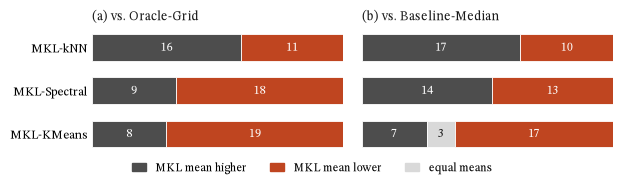

In [18]:
def plot_win_loss(results, savepath=None):
    # datasets x metrics where each MKL variant's mean is higher / equal / lower than each comparison method's
    rc = {"font.family": ["STIX Two Text", "Times New Roman", "STIXGeneral"],
          "mathtext.fontset": "stix", "font.size": 9, "pdf.fonttype": 42}
    shades  = {"higher": "#4d4d4d", "equal": "#d9d9d9", "lower": "#bf4520"}
    text_on = {"higher": "white", "equal": "#1a1a1a", "lower": "white"}
    label   = {"MKL-kNN": "MKL-kNN", "MKL-Spectral": "MKL-Spectral", "MKL-k-Means": "MKL-KMeans"}
    means   = {metric: dataset_means(results, metric) for metric in TEST_METRICS.values()}

    def counts(mkl, base):
        d = np.concatenate([(m[mkl] - m[base]).values for m in means.values()])
        return {"higher": int((d > 0).sum()), "equal": int((d == 0).sum()), "lower": int((d < 0).sum())}

    any_tie = any(counts(m, b)["equal"] for m in MKL_METHODS for b in BASELINES)
    n_pairs = len(DATASET_ORDER) * len(TEST_METRICS)
    with plt.rc_context(rc):
        fig, axes = plt.subplots(1, 2, figsize=(6.3, 1.85), sharey=True)
        for ax, base, tag in zip(axes, BASELINES, "ab"):
            for row, mkl in enumerate(MKL_METHODS[::-1]):
                left, c = 0, counts(mkl, base)
                for kind in ("higher", "equal", "lower"):
                    if c[kind]:
                        ax.barh(row, c[kind], left=left, height=0.62, color=shades[kind], edgecolor="white", linewidth=0.6)
                        ax.text(left + c[kind] / 2, row, str(c[kind]), ha="center", va="center",
                                color=text_on[kind], fontsize=8.5)
                    left += c[kind]
            ax.set_xlim(0, n_pairs)
            ax.set_xticks([])
            ax.set_yticks(range(len(MKL_METHODS)))
            ax.set_yticklabels([label[m] for m in MKL_METHODS[::-1]])
            ax.tick_params(axis="y", length=0)
            for side in ("top", "right", "left", "bottom"):
                ax.spines[side].set_visible(False)
            ax.set_title(f"({tag}) vs. {base}", fontsize=9.5, color="#1a1a1a", loc="left")
        kinds = ["higher", "lower"] + (["equal"] if any_tie else [])
        names = {"higher": "MKL mean higher", "lower": "MKL mean lower", "equal": "equal means"}
        fig.legend([plt.Rectangle((0, 0), 1, 1, color=shades[k]) for k in kinds], [names[k] for k in kinds],
                   loc="lower center", ncol=len(kinds), frameon=False, fontsize=8.5, handlelength=1.2,
                   bbox_to_anchor=(0.5, -0.02))
        fig.tight_layout(rect=(0, 0.08, 1, 1), w_pad=1.5)
        if savepath:
            fig.savefig(savepath, bbox_inches="tight", pad_inches=0.02)
    plt.show()


plot_win_loss(results, savepath=f"{FIG_DIR}/win_loss_datasets.pdf")

### 6.5 Ablations

MKL-kNN with the framework's settings against (a) the normalized combination, where each $K_m$ is divided by $\lVert H K_m H\rVert_F$, and (b) weights from NNLS on $M\eta = b$ instead of the quadratic program. Mean over the ten folds; the average rank is taken over the five methods, with all three MKL variants using the same setting. To refit an ablation, change `KERNEL_SCALING` or `SOLVER` in Section 1 and set `RUN_BENCHMARKS = True`.

In [19]:
def ablation_table(path, name):
    main = pd.read_csv(RESULTS_FILES[("raw", "qp")], float_precision="round_trip")
    other = pd.read_csv(path, float_precision="round_trip")
    columns = {}
    for label, metric in [("AUC-ROC", "auc_roc"), ("AUC-PR", "auc_pr")]:
        for setting, res in [("framework", main), (name, other)]:
            means = dataset_means(res, metric)
            columns[(label, setting)] = pd.concat([means["MKL-kNN"].round(3),
                                                   pd.Series({"Avg. rank": round(average_ranks(means)["MKL-kNN"], 2)})])
    return pd.DataFrame(columns)


display(ablation_table(RESULTS_FILES[("normalized", "qp")], "normalized"))
display(ablation_table(RESULTS_FILES[("raw", "nnls")], "NNLS"))

AUC-ROC               AUC-PR           
              framework normalized framework normalized
Ionosphere        0.971      0.964     0.966      0.953
Breast Cancer     0.958      0.963     0.939      0.943
Wine              0.957      0.959     0.899      0.901
Glass             0.961      0.944     0.888      0.857
Shuttle           0.984      0.972     0.922      0.885
Satellite         0.980      0.972     0.720      0.731
Churn             0.752      0.752     0.364      0.360
Mammography       0.789      0.629     0.411      0.234
Phoneme           0.855      0.845     0.706      0.665
Avg. rank         2.000      2.220     1.890      2.220

AUC-ROC           AUC-PR       
              framework   NNLS framework   NNLS
Ionosphere        0.971  0.970     0.966  0.962
Breast Cancer     0.958  0.962     0.939  0.943
Wine              0.957  0.956     0.899  0.889
Glass             0.961  0.969     0.888  0.903
Shuttle           0.984  0.965     0.922  0.877
Satellite         0.980  0.980     0.720  0.720
Churn             0.752  0.752     0.364  0.362
Mammography       0.789  0.791     0.411  0.413
Phoneme           0.855  0.856     0.706  0.707
Avg. rank         2.000  1.890     1.890  1.890

### 6.6 Sensitivity

Mean AUC-ROC over Ionosphere, Breast Cancer, Wine and Glass when one parameter is varied and the others keep their defaults. In the ν rows the same ν is used for all four datasets.

In [20]:
SENSITIVITY_DATASETS = ["Ionosphere", "Breast Cancer", "Wine", "Glass"]
SENSITIVITY_GRID     = {"k": [5, 10, 15, 20], "k_c": [2, 3, 4, 6], "nu": list(NU_GRID)}

if RUN_SENSITIVITY:
    sens = pd.concat([evaluate_dataset(*LOADED[d], **{p: v}).assign(dataset=d, param=p, value=v)
                      for p, values in SENSITIVITY_GRID.items() for d in SENSITIVITY_DATASETS for v in values])
    sens.to_csv(SENSITIVITY_CSV, index=False)
else:
    sens = pd.read_csv(SENSITIVITY_CSV, float_precision="round_trip")

(sens.groupby(["param", "value", "method"])["auc_roc"].mean().unstack("method")[METHODS]
     .reindex(list(SENSITIVITY_GRID), level="param").round(3))

method       Oracle-Grid  Baseline-Median  MKL-k-Means  MKL-Spectral  MKL-kNN
param value                                                                  
k     5.00         0.956            0.961        0.946         0.955    0.960
      10.00        0.956            0.961        0.946         0.956    0.962
      15.00        0.956            0.961        0.946         0.955    0.963
      20.00        0.956            0.961        0.946         0.955    0.962
k_c   2.00         0.956            0.961        0.945         0.949    0.962
      3.00         0.956            0.961        0.946         0.956    0.962
      4.00         0.956            0.961        0.945         0.960    0.962
      6.00         0.956            0.961        0.959         0.959    0.962
nu    0.01         0.960            0.968        0.932         0.967    0.964
      0.05         0.961            0.968        0.930         0.965    0.964
      0.10         0.957            0.965        0.941         0.962    0.964
      0.20         0.956            0.961        0.946         0.956    0.963
      0.30         0.956            0.962        0.949         0.957    0.962

### 6.7 Effect sizes (Appendix A)

For each dataset: the mean paired difference over the ten folds (MKL variant minus comparison method) and, in brackets, the matched-pairs rank-biserial correlation.

In [21]:
def rank_biserial(d):
    d = d[d != 0]
    if len(d) == 0:
        return 0.0
    r = rankdata(np.abs(d))
    return float((r[d > 0].sum() - r[d < 0].sum()) / r.sum())


def effect_sizes(results, base):
    cells = {}
    for d in DATASET_ORDER:
        sub = results[results.dataset == d]
        for mkl in MKL_METHODS:
            for label, metric in TEST_METRICS.items():
                folds = sub.pivot_table(index="fold", columns="method", values=metric)
                diff = (folds[mkl] - folds[base]).values
                cells[(d, mkl, label)] = f"{diff.mean():+.3f} ({rank_biserial(diff):+.2f})"
    return (pd.Series(cells).unstack([1, 2])
              .reindex(index=DATASET_ORDER, columns=pd.MultiIndex.from_product([MKL_METHODS, list(TEST_METRICS)])))


for base in BASELINES:
    print(f"vs {base}")
    display(effect_sizes(results, base))

vs Oracle-Grid


MKL-kNN                                    MKL-Spectral  \
                      AUC-ROC          AUC-PR      F1-anomaly         AUC-ROC   
Ionosphere     +0.008 (+0.79)  +0.008 (+0.39)  +0.028 (+0.33)  -0.014 (-0.85)   
Breast Cancer  -0.004 (-0.35)  -0.002 (-0.16)  -0.083 (-1.00)  -0.001 (-0.51)   
Wine           +0.029 (+1.00)  +0.070 (+1.00)  +0.094 (+0.90)  +0.027 (+0.87)   
Glass          -0.009 (-0.50)  -0.022 (-0.57)  +0.047 (+0.71)  -0.012 (-0.50)   
Shuttle        -0.011 (-1.00)  -0.054 (-1.00)  -0.003 (+0.31)  -0.024 (-1.00)   
Satellite      +0.001 (+0.27)  +0.011 (-0.09)  +0.004 (+0.24)  -0.097 (-0.78)   
Churn          +0.002 (+0.02)  +0.005 (-0.16)  +0.034 (+0.64)  -0.015 (-0.96)   
Mammography    -0.080 (-0.93)  +0.040 (+0.64)  +0.114 (+1.00)  -0.116 (-1.00)   
Phoneme        -0.014 (-1.00)  -0.029 (-1.00)  +0.010 (+0.96)  -0.216 (-1.00)   

                                                  MKL-k-Means                  \
                       AUC-PR      F1-anomaly         AUC-ROC          AUC-PR   
Ionosphere     -0.015 (-0.71)  +0.078 (+0.62)  -0.023 (-1.00)  -0.025 (-0.85)   
Breast Cancer  -0.002 (-0.51)  -0.016 (-0.64)  -0.001 (-0.60)  -0.002 (-0.56)   
Wine           +0.058 (+1.00)  +0.133 (+1.00)  +0.029 (+0.90)  +0.063 (+1.00)   
Glass          -0.028 (-0.50)  +0.168 (+1.00)  -0.044 (-0.93)  -0.059 (-0.93)   
Shuttle        -0.076 (-1.00)  +0.187 (+1.00)  -0.188 (-1.00)  -0.255 (-1.00)   
Satellite      -0.056 (-0.60)  +0.440 (+1.00)  -0.101 (-0.85)  -0.059 (-0.64)   
Churn          -0.042 (-1.00)  -0.022 (-0.27)  -0.015 (-0.96)  -0.040 (-1.00)   
Mammography    +0.000 (+0.09)  +0.132 (+0.71)  -0.299 (-1.00)  -0.156 (-1.00)   
Phoneme        -0.289 (-1.00)  -0.111 (-1.00)  -0.227 (-1.00)  -0.298 (-1.00)   

                               
                   F1-anomaly  
Ionosphere     +0.067 (+0.62)  
Breast Cancer  -0.009 (-0.53)  
Wine           +0.142 (+1.00)  
Glass          +0.134 (+1.00)  
Shuttle        +0.038 (+0.38)  
Satellite      +0.459 (+1.00)  
Churn          -0.022 (-0.27)  
Mammography    +0.019 (-0.05)  
Phoneme        -0.125 (-1.00)

vs Baseline-Median


MKL-kNN                                    MKL-Spectral  \
                      AUC-ROC          AUC-PR      F1-anomaly         AUC-ROC   
Ionosphere     +0.006 (+0.20)  +0.002 (-0.05)  -0.055 (-1.00)  -0.016 (-1.00)   
Breast Cancer  -0.002 (-0.33)  -0.001 (-0.02)  -0.068 (-1.00)  +0.000 (+1.00)   
Wine           +0.003 (+0.20)  +0.012 (+0.60)  -0.045 (-1.00)  +0.000 (+0.33)   
Glass          -0.003 (-0.33)  -0.019 (-0.73)  -0.117 (-1.00)  -0.006 (-1.00)   
Shuttle        +0.010 (+1.00)  +0.015 (+1.00)  -0.193 (-1.00)  -0.003 (-1.00)   
Satellite      +0.103 (+0.89)  +0.070 (+0.67)  -0.455 (-1.00)  +0.005 (+1.00)   
Churn          +0.017 (+1.00)  +0.045 (+1.00)  +0.057 (+0.93)  -0.001 (-0.45)   
Mammography    +0.102 (+1.00)  +0.171 (+1.00)  +0.038 (+0.27)  +0.067 (+1.00)   
Phoneme        +0.213 (+1.00)  +0.269 (+1.00)  +0.134 (+1.00)  +0.011 (+1.00)   

                                                  MKL-k-Means                  \
                       AUC-PR      F1-anomaly         AUC-ROC          AUC-PR   
Ionosphere     -0.021 (-1.00)  -0.005 (-0.07)  -0.025 (-1.00)  -0.031 (-1.00)   
Breast Cancer  -0.001 (-0.33)  +0.000 (+0.30)  +0.001 (+0.42)  -0.001 (-0.24)   
Wine           +0.001 (+0.33)  -0.006 (-1.00)  +0.002 (+0.67)  +0.006 (+0.67)   
Glass          -0.025 (-1.00)  +0.005 (+0.33)  -0.037 (-1.00)  -0.057 (-1.00)   
Shuttle        -0.008 (-1.00)  -0.003 (-1.00)  -0.167 (-1.00)  -0.186 (-1.00)   
Satellite      +0.003 (+0.38)  -0.019 (-1.00)  +0.000 (+0.00)  +0.000 (+0.00)   
Churn          -0.002 (-0.82)  +0.001 (+0.16)  +0.000 (+0.24)  -0.000 (-0.27)   
Mammography    +0.132 (+1.00)  +0.055 (+0.31)  -0.117 (-1.00)  -0.025 (-0.49)   
Phoneme        +0.009 (+1.00)  +0.013 (+0.96)  -0.000 (-0.96)  -0.000 (-0.73)   

                               
                   F1-anomaly  
Ionosphere     -0.016 (-0.35)  
Breast Cancer  +0.007 (+0.46)  
Wine           +0.003 (+0.33)  
Glass          -0.030 (-0.54)  
Shuttle        -0.152 (-1.00)  
Satellite      +0.000 (+0.00)  
Churn          +0.001 (+1.00)  
Mammography    -0.058 (-0.27)  
Phoneme        -0.001 (-0.60)

## 7. Software versions

In [22]:
pd.Series({"Python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
           "scikit-learn": sklearn.__version__, "statsmodels": statsmodels.__version__,
           "pandas": pd.__version__, "matplotlib": matplotlib.__version__}, name="version").to_frame()

,version
Python,3.12.2
numpy,1.26.4
scipy,1.13.0
scikit-learn,1.4.2
statsmodels,0.15.0
pandas,3.0.5
matplotlib,3.11.1
